# SHAP Analysis

This notebook uses SHAP to interpret the best-performing
machine-learning model.

SHAP helps explain how individual features contribute
to the model's predictions.

## Workflow

1. Import libraries
2. Load the trained model
3. Load the training and testing datasets
4. Transform the features using the trained pipeline
5. Create a SHAP explainer
6. Calculate SHAP values
7. Visualize feature importance
8. Save SHAP results and figures

## 1. Import Libraries

Import the libraries required for model loading,
data processing, and SHAP analysis.

In [1]:
import sys
import json
import joblib
import shap

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path


# Locate the project directory.
PROJECT_ROOT = Path.cwd()

while (
    not (PROJECT_ROOT / "src").exists()
    and PROJECT_ROOT != PROJECT_ROOT.parent
):
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError(
        "Could not locate the project's src directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from src.config import (
    PROCESSED_DATA_DIR,
    MODELS_DIR,
    FIGURES_DIR,
    METRICS_DIR
)

from src.preprocessing import load_saved_split


print("Libraries imported successfully.")

C:\Users\david\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.


## 2. Load Trained Model

Load the best-performing model saved during
the model training process.

Also load its metadata to identify the selected
model and relevant configuration.

In [2]:
MODEL_PATH = (
    MODELS_DIR / "best_model.joblib"
)

METADATA_PATH = (
    MODELS_DIR / "model_metadata.json"
)


if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "Trained model not found. "
        "Run 03_model_training.ipynb first."
    )


best_model = joblib.load(
    MODEL_PATH
)


with open(
    METADATA_PATH,
    "r"
) as file:

    model_metadata = json.load(file)


print("Model loaded successfully.")

print(
    "Selected Model:",
    model_metadata["best_model_name"]
)

Model loaded successfully.
Selected Model: Random Forest


## 3. Load Training and Testing Data

Load the same datasets used during model training.

The training dataset will provide background samples
for SHAP.

The testing dataset will be used to explain predictions.

In [3]:
X_train, y_train = load_saved_split(
    PROCESSED_DATA_DIR / "train.csv"
)

X_test, y_test = load_saved_split(
    PROCESSED_DATA_DIR / "test.csv"
)


print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (50, 18656)
Testing data: (13, 18656)


## 4. Transform Features

Use the preprocessing steps already fitted inside
the selected machine-learning pipeline.

This includes:

- Missing-value imputation
- Feature selection
- Scaling, when used by the selected model

The SHAP explainer will receive the transformed
features that the final classifier actually uses.

In [4]:
# Get the preprocessing steps from the trained pipeline.
preprocessing_pipeline = best_model[:-1]

# Transform training and testing features.
X_train_transformed = preprocessing_pipeline.transform(
    X_train
)

X_test_transformed = preprocessing_pipeline.transform(
    X_test
)


# Retrieve the selected feature names.
feature_selector = best_model.named_steps[
    "feature_selection"
]

selected_features = X_train.columns[
    feature_selector.get_support()
].tolist()


# Convert transformed arrays into DataFrames.
X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=selected_features
)

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=selected_features
)


print(
    "Number of selected features:",
    len(selected_features)
)

print("\nSelected Features:")
print(selected_features)

print("\nTransformed testing data:")
display(X_test_transformed_df.head())

Number of selected features: 50

Selected Features:
['ABCA8', 'AGBL5', 'AGTPBP1', 'ANKMY2', 'ANO5', 'ARF6', 'ARG2', 'ARV1///ARV1', 'ATP2B2', 'ATP8B4', 'ATPAF2', 'CCL22', 'CCR7', 'CD2', 'CD84', 'CD86', 'CDKL5', 'CEMIP', 'COG2', 'CRTAM', 'CYP3A7-CYP3A51P///CYP3A7', 'FAIM2', 'FERMT3', 'FLG2', 'GALC', 'GLRA2', 'IL7R', 'KIAA1958', 'KIF4A', 'KLHL12', 'KLHL6', 'MEIS3///MEIS3P1', 'MGC20647', 'MOCS2', 'MPP1', 'NEFL', 'PARK2', 'PCOLCE2', 'PHACTR1', 'PTCH1', 'PTPRC', 'RASGRP1', 'RASSF2', 'RGS13', 'SGSM1', 'SLC11A1', 'SMAD9', 'SPIDR', 'STK33', 'TUBGCP5']

Transformed testing data:


,ABCA8,AGBL5,AGTPBP1,ANKMY2,ANO5,ARF6,ARG2,ARV1///ARV1,ATP2B2,ATP8B4,...,PTPRC,RASGRP1,RASSF2,RGS13,SGSM1,SLC11A1,SMAD9,SPIDR,STK33,TUBGCP5
0,4.49,6.62,7.64,7.90,8.06,8.62,8.13,9.17,5.05,4.50,...,4.85,7.46,5.65,4.65,7.40,4.89,6.97,8.39,7.46,6.91
1,4.27,6.09,7.18,6.94,6.44,9.02,6.10,8.49,5.05,4.77,...,5.21,5.59,5.51,4.80,6.22,5.40,6.19,8.17,6.23,6.14
2,4.00,6.61,7.70,7.91,7.94,9.10,7.74,9.11,5.05,3.91,...,4.04,7.03,4.93,3.77,6.92,5.43,6.81,8.51,7.28,6.84
3,4.40,6.48,7.58,7.82,7.79,8.72,7.93,9.07,5.29,4.13,...,5.21,7.20,5.05,3.90,6.83,5.46,7.03,8.48,7.05,6.39
4,3.63,6.38,7.30,7.30,7.39,9.16,7.79,8.82,5.08,4.17,...,4.56,6.57,5.06,4.15,6.58,5.41,6.68,8.40,7.23,6.56


## 5. Prepare SHAP Samples

Select a background sample from the training data.

Select a smaller group of testing samples for explanation.

Using a sample helps reduce computation time, especially
when the dataset contains many observations or features.

In [5]:
BACKGROUND_SIZE = min(
    100,
    len(X_train_transformed_df)
)

EXPLANATION_SIZE = min(
    200,
    len(X_test_transformed_df)
)


background = X_train_transformed_df.sample(
    n=BACKGROUND_SIZE,
    random_state=42
)

X_explain = X_test_transformed_df.sample(
    n=EXPLANATION_SIZE,
    random_state=42
)


print("Background samples:", background.shape)

print("Samples to explain:", X_explain.shape)

Background samples: (50, 50)
Samples to explain: (13, 50)


## 6. Create SHAP Explainer

Retrieve the final classifier from the trained pipeline.

Create a SHAP explainer using the selected classifier
and training background samples.

SHAP will estimate how each selected feature contributes
to the classifier's output.

In [6]:
classifier = best_model.named_steps[
    "classifier"
]


explainer = shap.Explainer(
    classifier,
    background
)


print("SHAP explainer created successfully.")

SHAP explainer created successfully.


## 7. Calculate SHAP Values

Calculate SHAP values for the selected testing samples.

For binary classification, the positive class
(class 1) is used when SHAP returns separate values
for both classes.

In [7]:
shap_values = explainer(
    X_explain
)


# Handle SHAP outputs that contain separate values
# for each class.
if len(shap_values.shape) == 3:

    shap_values = shap_values[:, :, 1]


print("SHAP values calculated successfully.")

print("SHAP value shape:", shap_values.shape)

SHAP values calculated successfully.
SHAP value shape: (13, 50)


## 8. SHAP Summary Plot

Create a SHAP beeswarm summary plot.

The plot shows:

- Which features have the greatest influence
- Whether feature values increase or decrease
  the model output
- The distribution of feature contributions
  across the explained samples

The SHAP values explain the model output and
should not be interpreted as proof of a causal
relationship.

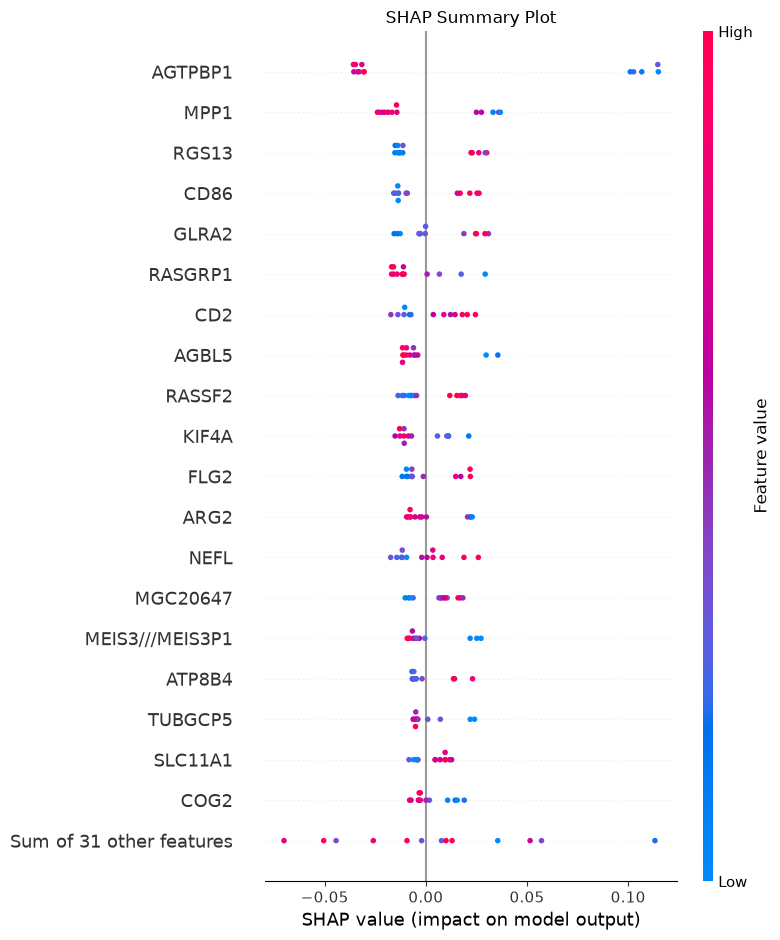

SHAP summary plot saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\figures\shap_summary.png


In [8]:
plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary Plot"
)

plt.tight_layout()


summary_plot_path = (
    FIGURES_DIR / "shap_summary.png"
)

plt.savefig(
    summary_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary plot saved to:")
print(summary_plot_path)

## 9. SHAP Feature Importance

Calculate the mean absolute SHAP value for each feature.

A larger mean absolute SHAP value indicates that a
feature has a greater average contribution to the
model output across the explained samples.

In [9]:
feature_importance = np.abs(
    shap_values.values
).mean(axis=0)


shap_importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Mean Absolute SHAP Value": feature_importance
})


shap_importance_df = shap_importance_df.sort_values(
    by="Mean Absolute SHAP Value",
    ascending=False
).reset_index(drop=True)


display(
    shap_importance_df.head(20)
)

,Feature,Mean Absolute SHAP Value
0,AGTPBP1,0.061967
1,MPP1,0.023956
2,RGS13,0.018277
3,CD86,0.016193
4,GLRA2,0.013907
5,RASGRP1,0.013768
6,CD2,0.013075
7,AGBL5,0.012241
8,RASSF2,0.011632
9,KIF4A,0.011435


## 10. SHAP Feature Importance Bar Plot

Visualize the average absolute SHAP values.

The features with the largest values have the highest
average influence on the model output.

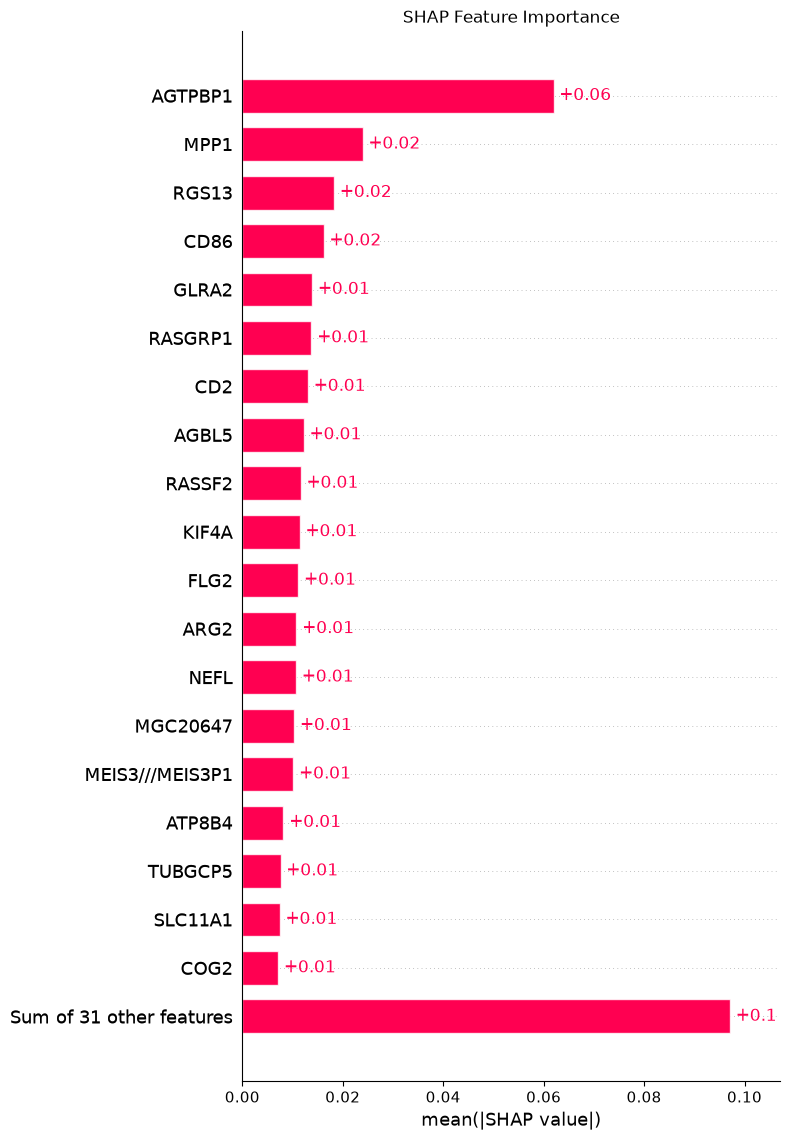

Feature importance plot saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\figures\shap_feature_importance.png


In [10]:
plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Feature Importance"
)

plt.tight_layout()


importance_plot_path = (
    FIGURES_DIR / "shap_feature_importance.png"
)

plt.savefig(
    importance_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance plot saved to:")
print(importance_plot_path)

## 11. Save SHAP Results

Save the feature importance ranking as a CSV file.

This allows the results to be reviewed and used in
the project's final report.

In [11]:
shap_results_path = (
    METRICS_DIR / "shap_feature_importance.csv"
)


shap_importance_df.to_csv(
    shap_results_path,
    index=False
)


print("SHAP feature importance saved to:")
print(shap_results_path)

SHAP feature importance saved to:
C:\Users\david\Documents\Code\Distributed-System-for-AI-Based-Diabetes-Prediction\results\metrics\shap_feature_importance.csv


## 12. SHAP Analysis Summary

The SHAP analysis is complete.

The selected machine-learning model has been interpreted
using feature-level SHAP values.

The results include:

- SHAP summary plot
- SHAP feature importance plot
- Ranked feature importance CSV

These results help explain which features contribute
most to the model's predictions.

SHAP results describe model behavior and do not establish
that a feature causes diabetes.